In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split


### Data Loading

In [34]:
exec_file = pd.ExcelFile('D:\\Data science\\Assignments\\Questions\\Decision Tree (1)\\Decision Tree\\heart_disease.xlsx')
print(exec_file.sheet_names)

['Description', 'Heart_disease']


In [35]:
df = exec_file.parse('Heart_disease')
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
903,53,Male,asymptomatic,125,0,False,normal,120,False,1.5,upsloping,reversable defect,4
904,62,Male,asymptomatic,166,170,False,st-t abnormality,120,True,3.0,flat,reversable defect,4
905,56,Male,non-anginal,170,0,False,lv hypertrophy,123,True,2.5,downsloping,normal,4
906,56,Male,non-anginal,144,208,True,st-t abnormality,105,TURE,NaN,downsloping,fixed defect,4


### EDA

In [36]:
display(df.head())
display(df.info())
display(df.isnull().sum())

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,thal,num
0,63,Male,typical angina,145,233,True,lv hypertrophy,150,False,2.3,downsloping,fixed defect,0
1,41,Male,atypical angina,135,203,False,normal,132,False,0.0,flat,fixed defect,0
2,57,Male,asymptomatic,140,192,False,normal,148,False,0.4,flat,fixed defect,0
3,52,Male,typical angina,118,186,False,lv hypertrophy,190,False,0.0,flat,fixed defect,0
4,57,Male,asymptomatic,110,201,False,normal,126,True,1.5,flat,fixed defect,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    object 
 2   cp        908 non-null    object 
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    bool   
 6   restecg   908 non-null    object 
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    object 
 11  thal      908 non-null    object 
 12  num       908 non-null    int64  
dtypes: bool(1), float64(1), int64(5), object(6)
memory usage: 86.1+ KB


None

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

In [40]:
# there are 908 rows and oldpeak has 62 null values so its better to remove the oldpeak col
df = df.drop(columns=['oldpeak'])
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
slope       0
thal        0
num         0
dtype: int64

In [41]:
# there is mistake in the data of col 'exang' lets handle that first
df['exang'] = df['exang'].astype(str)
df['exang'] = df['exang'].replace({'TRUE': 'True', 'FALSE': 'False', 'TURE': 'True'})
df['exang'].value_counts()

exang
False    535
True     373
Name: count, dtype: int64

### Visulization

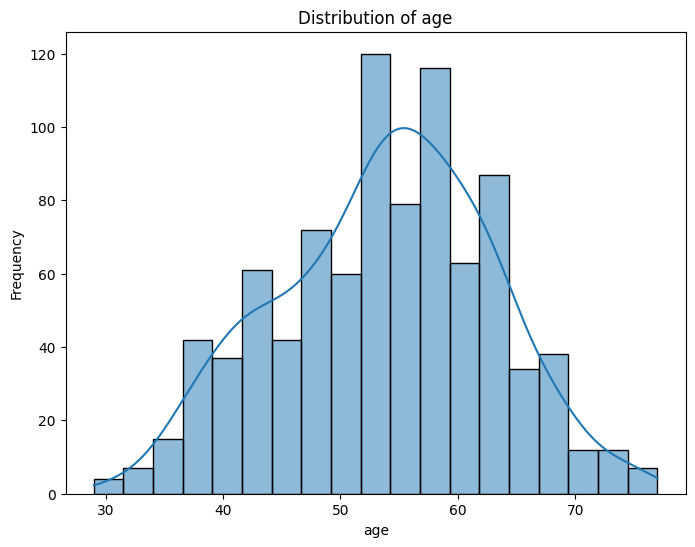

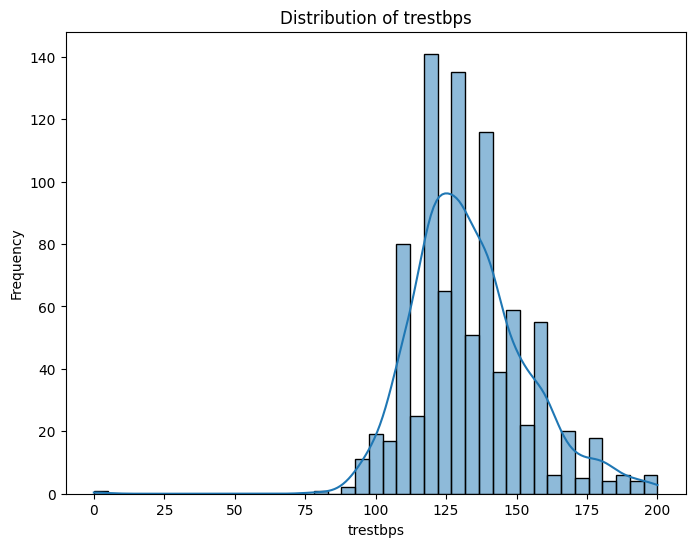

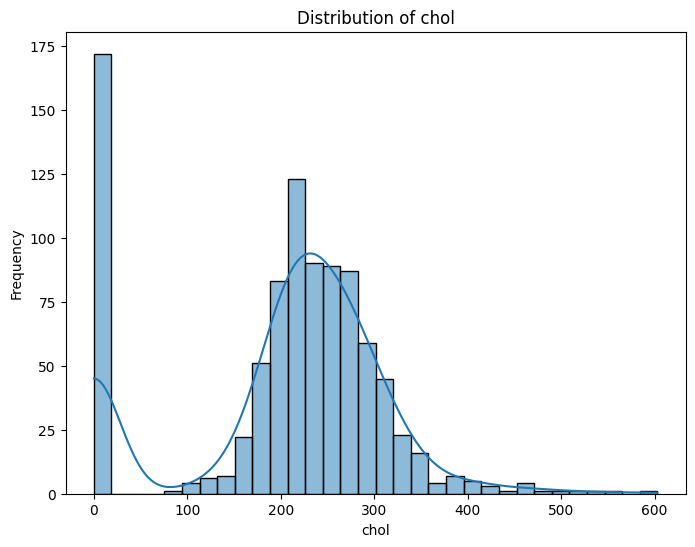

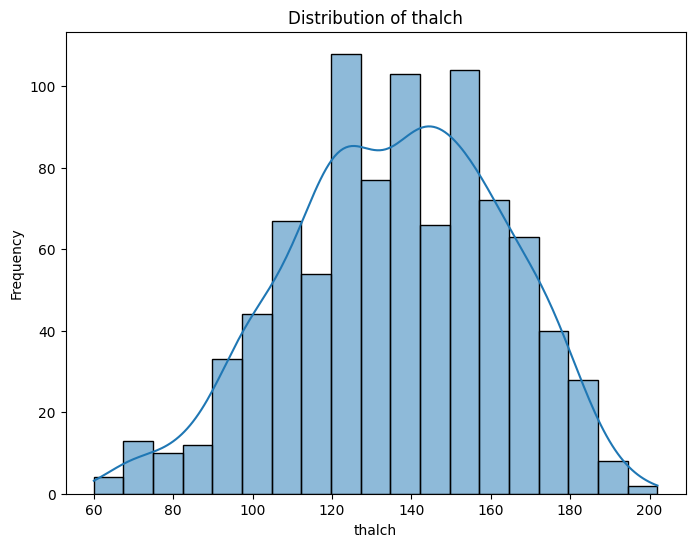

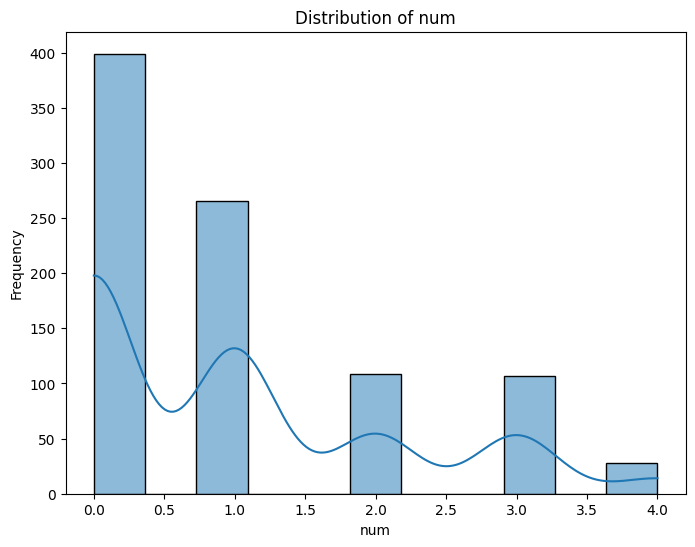

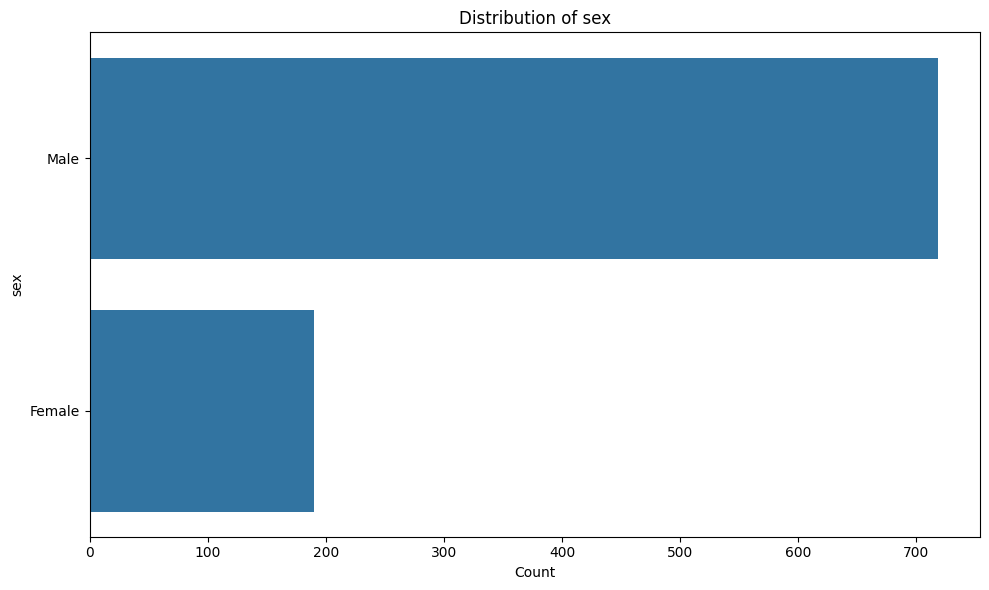

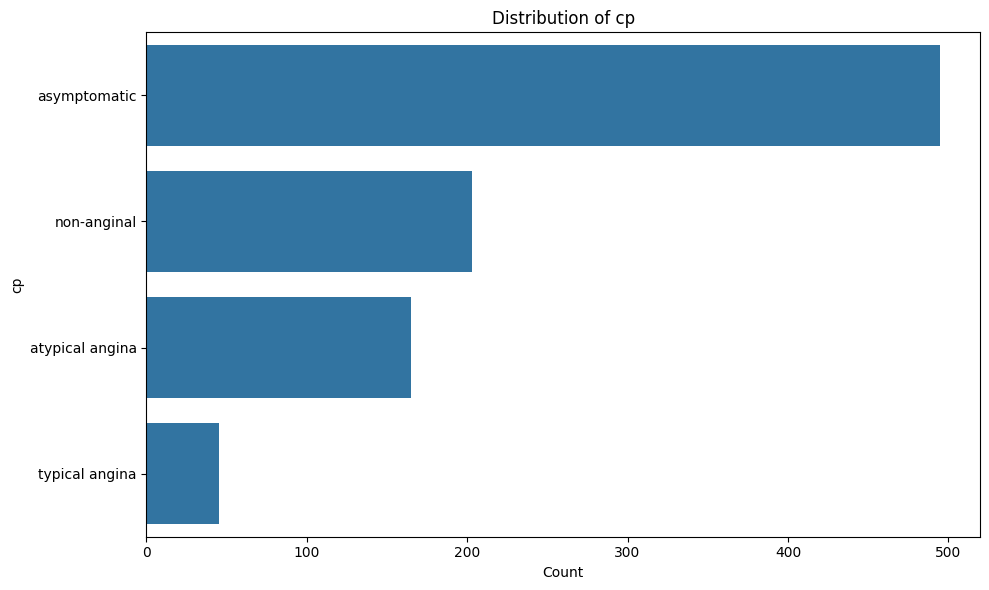

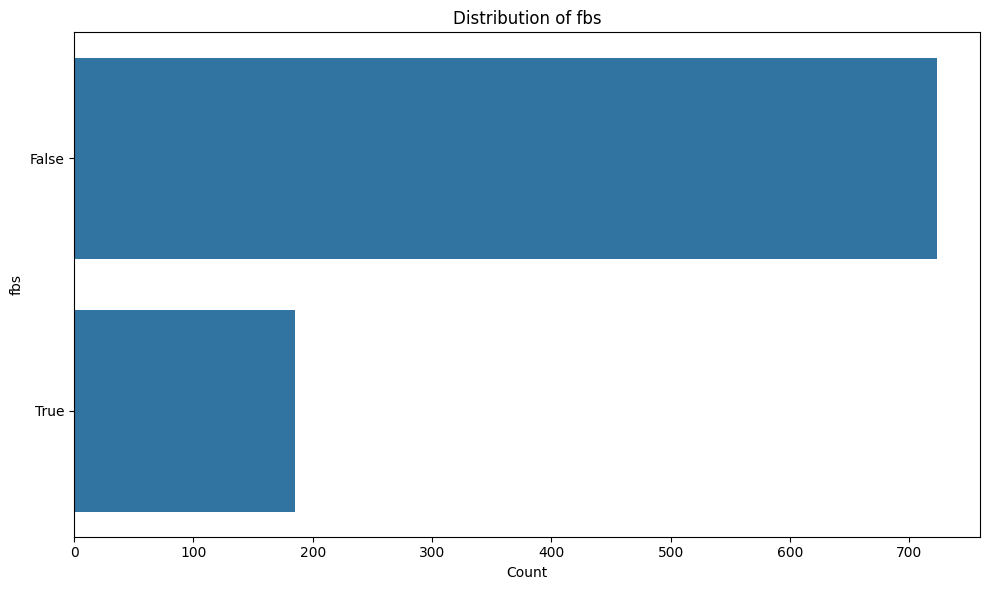

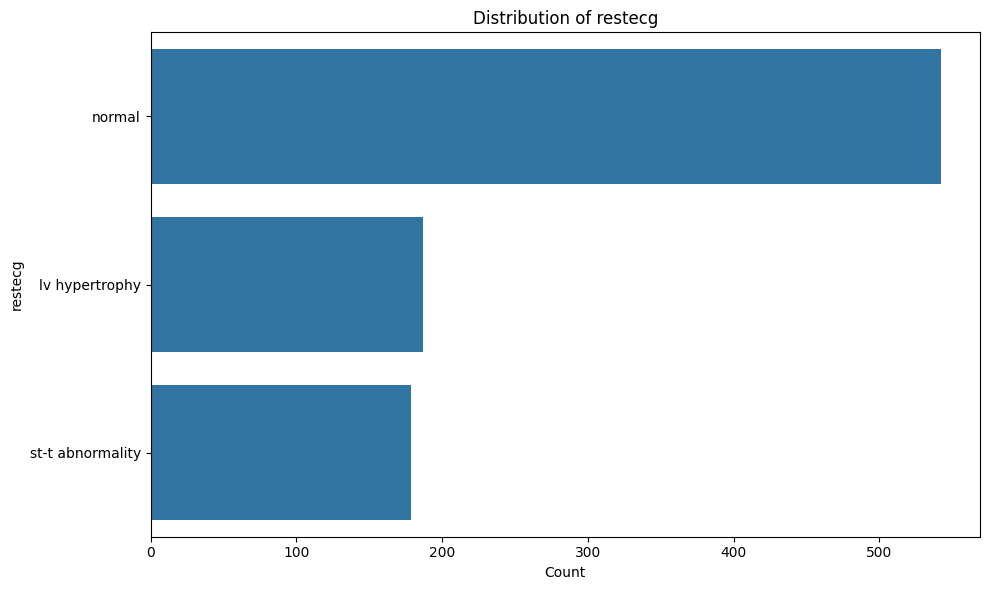

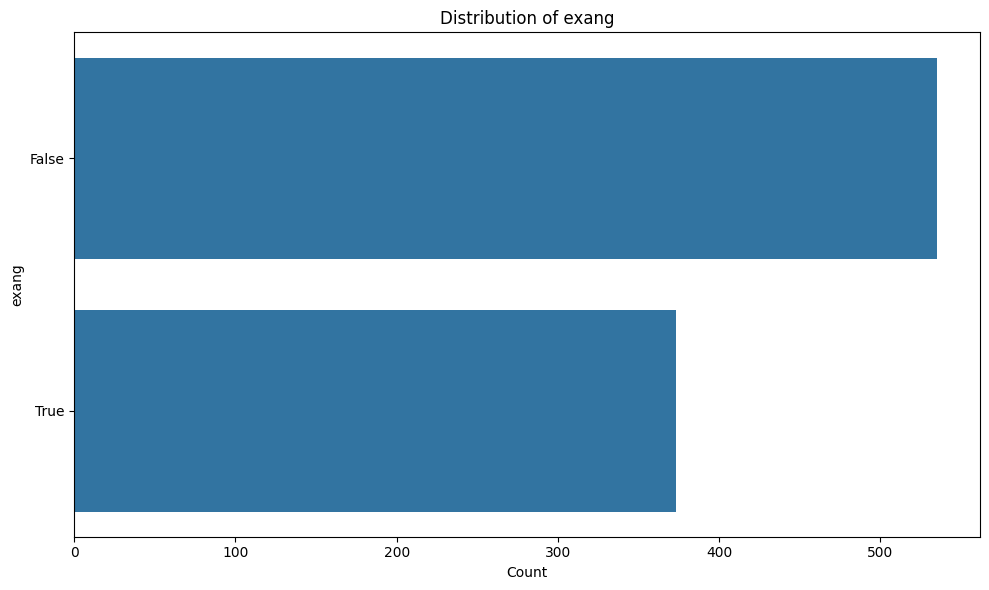

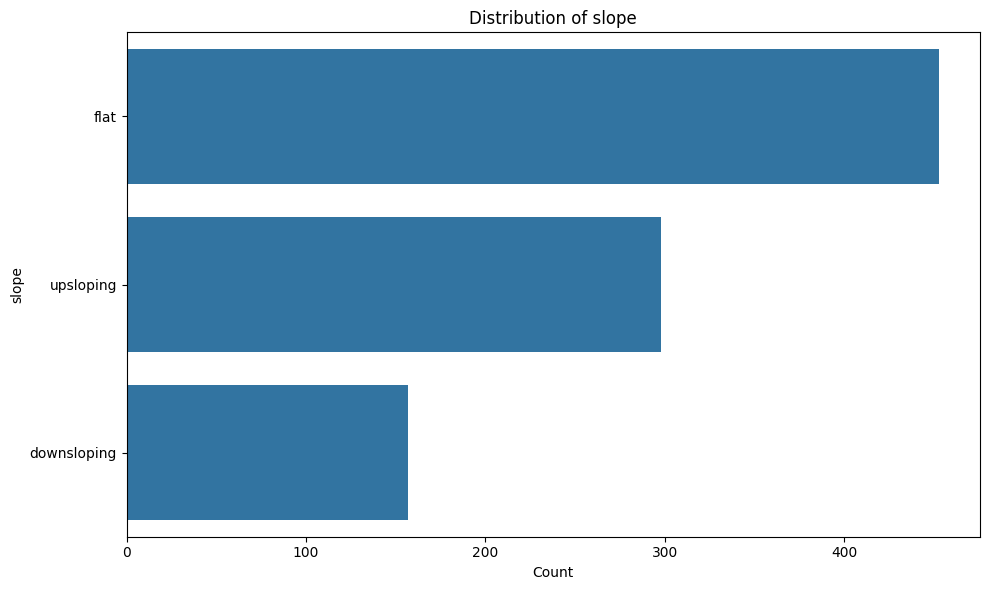

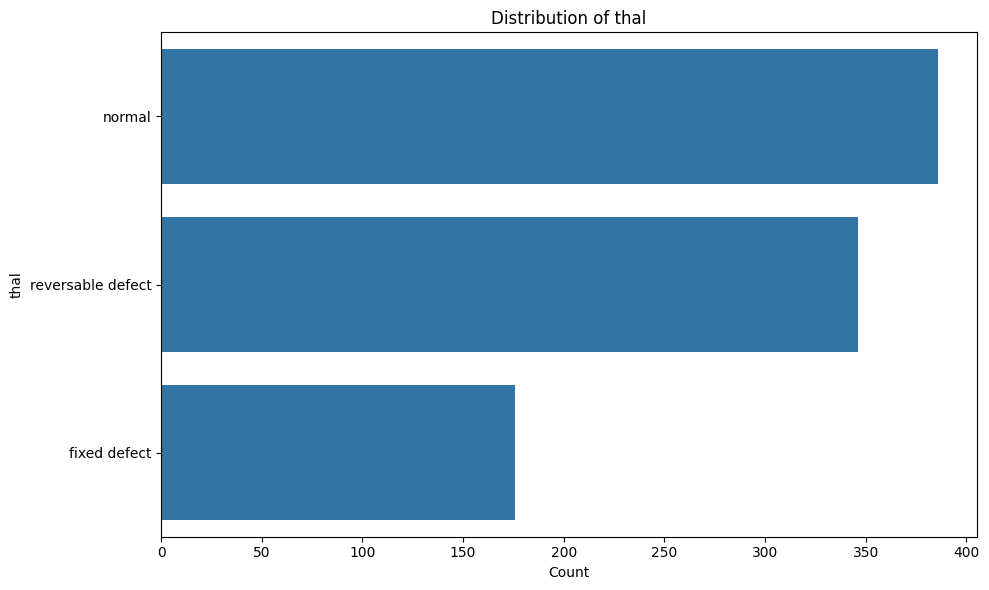

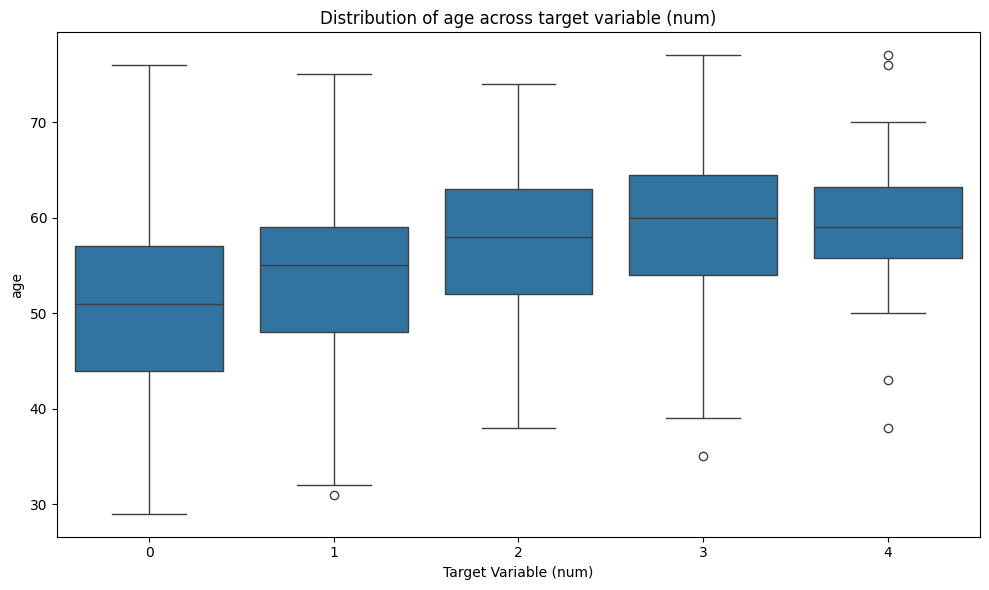

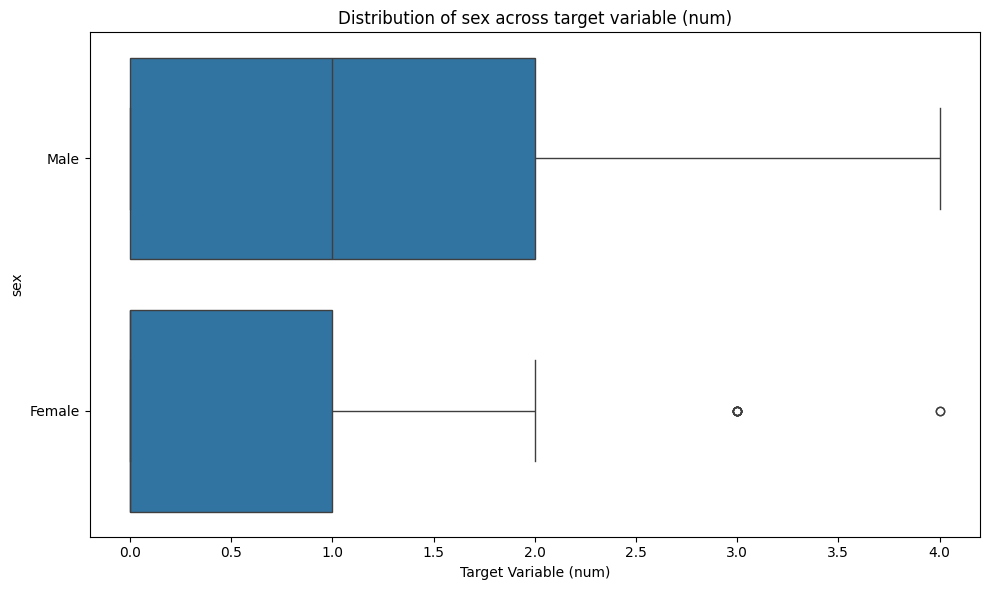

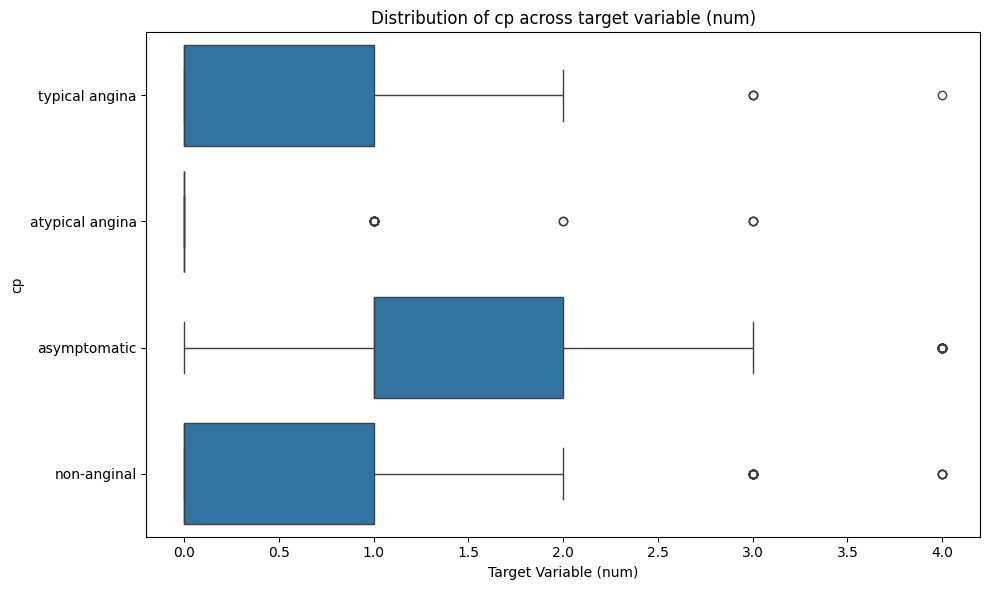

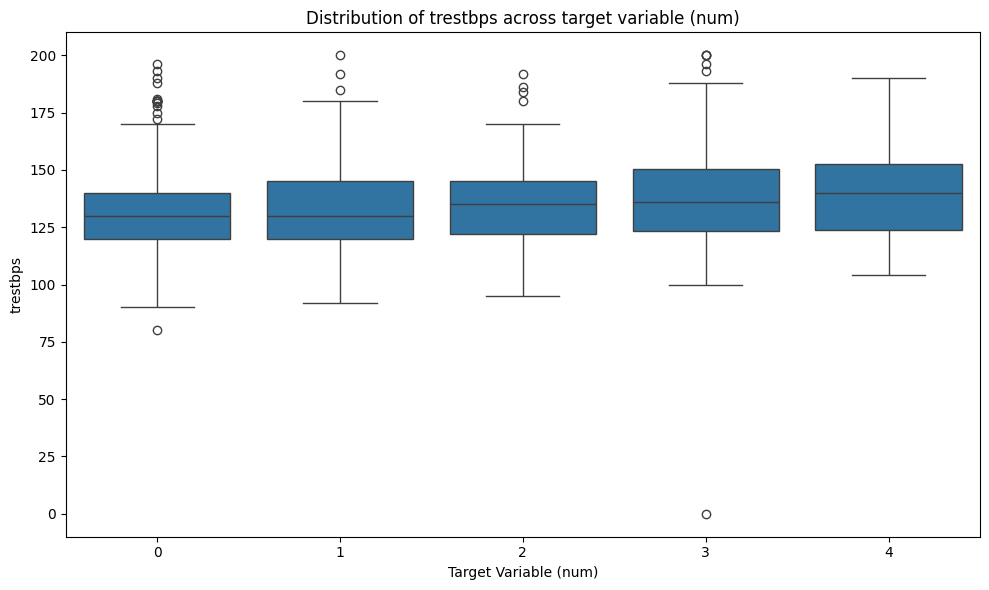

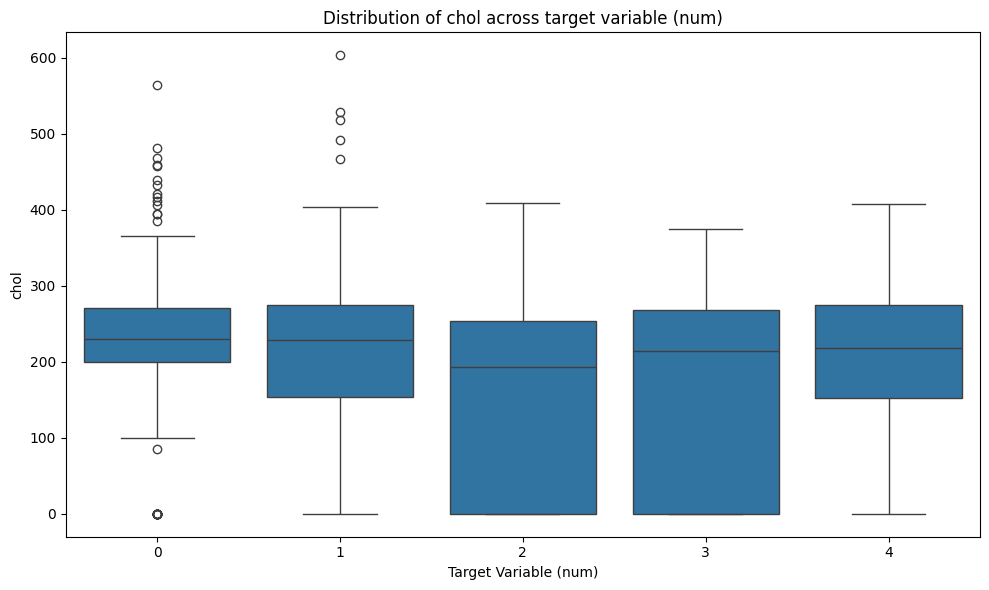

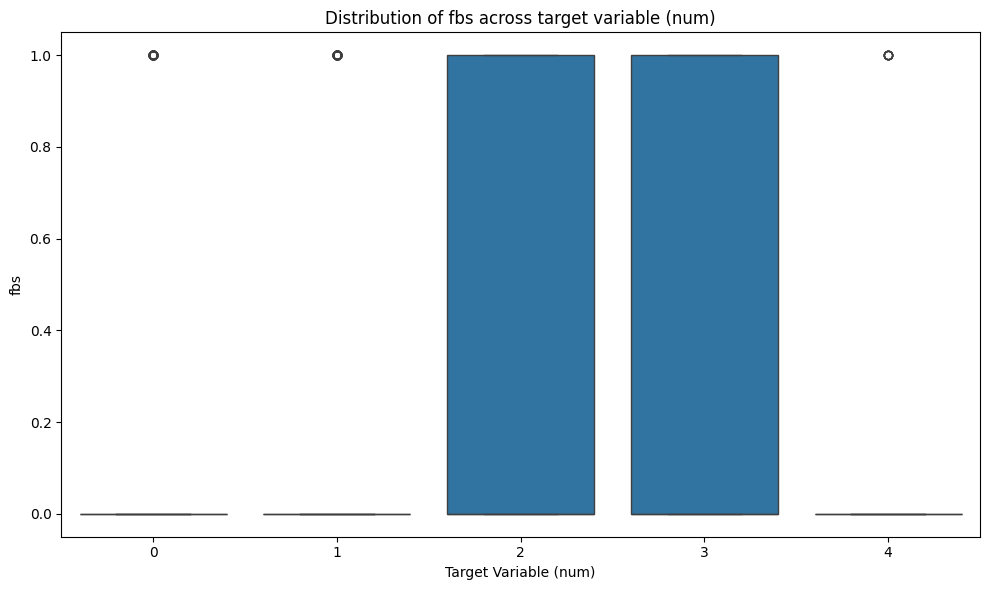

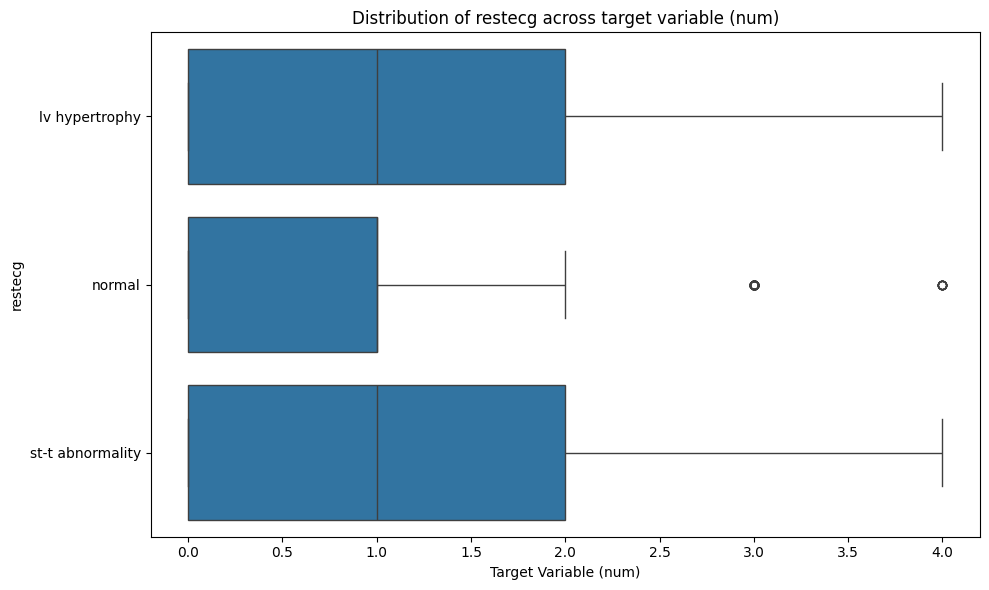

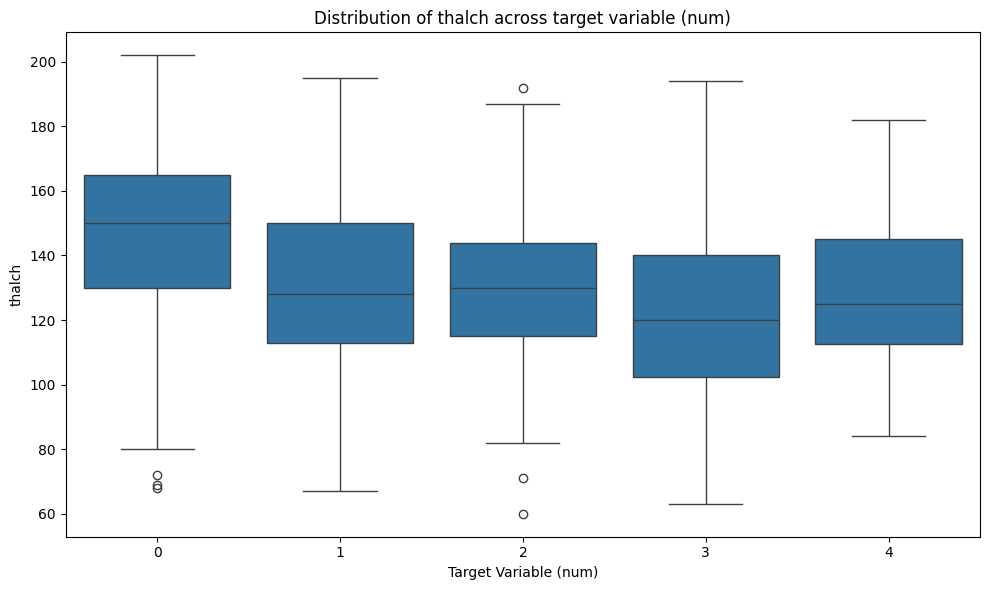

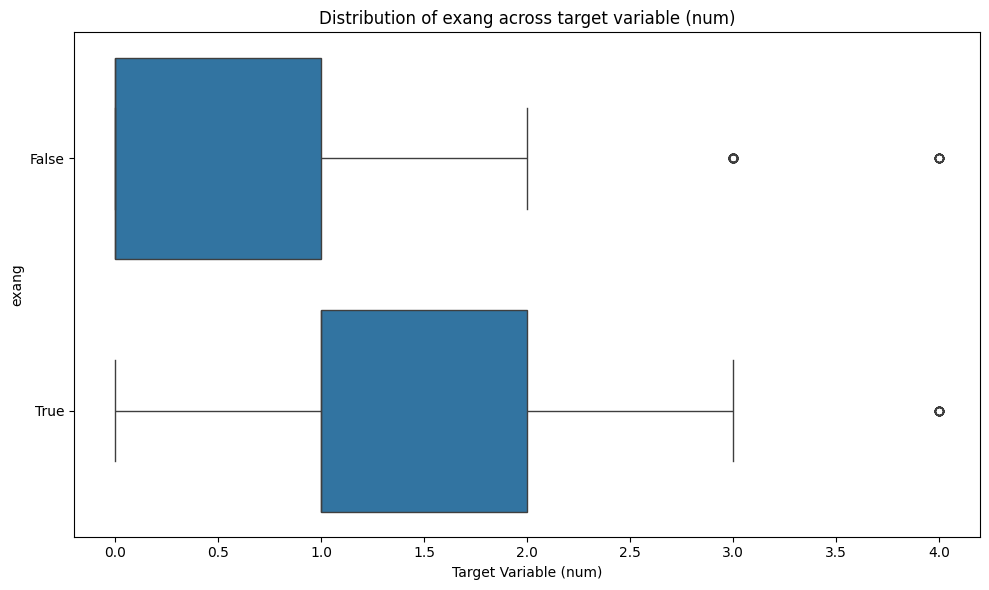

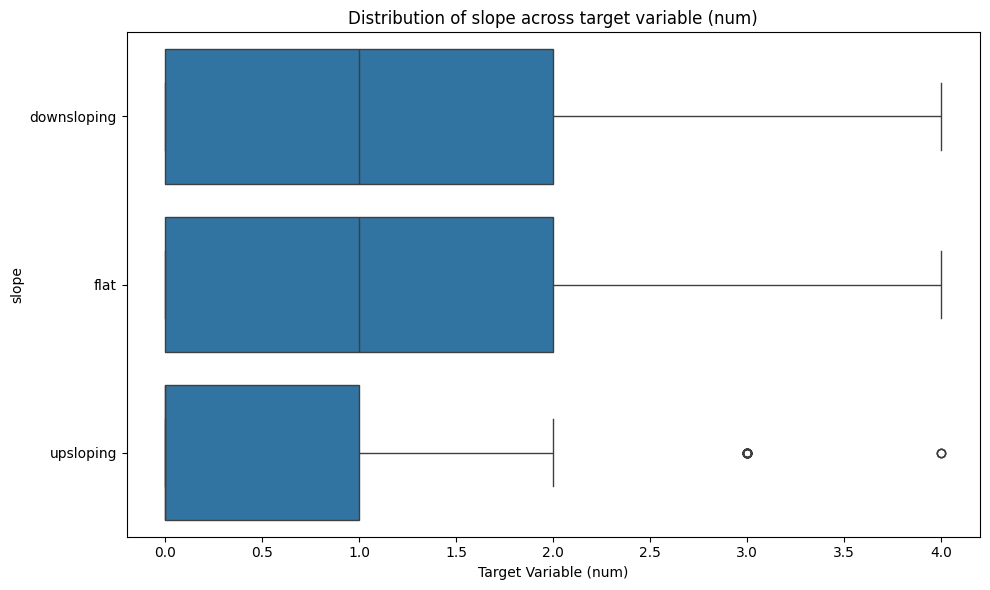

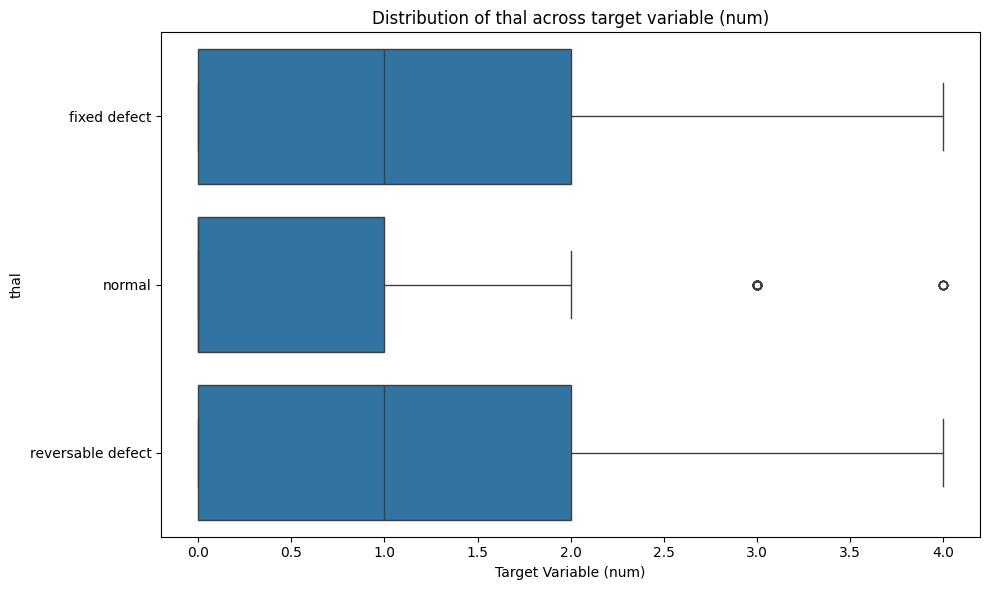

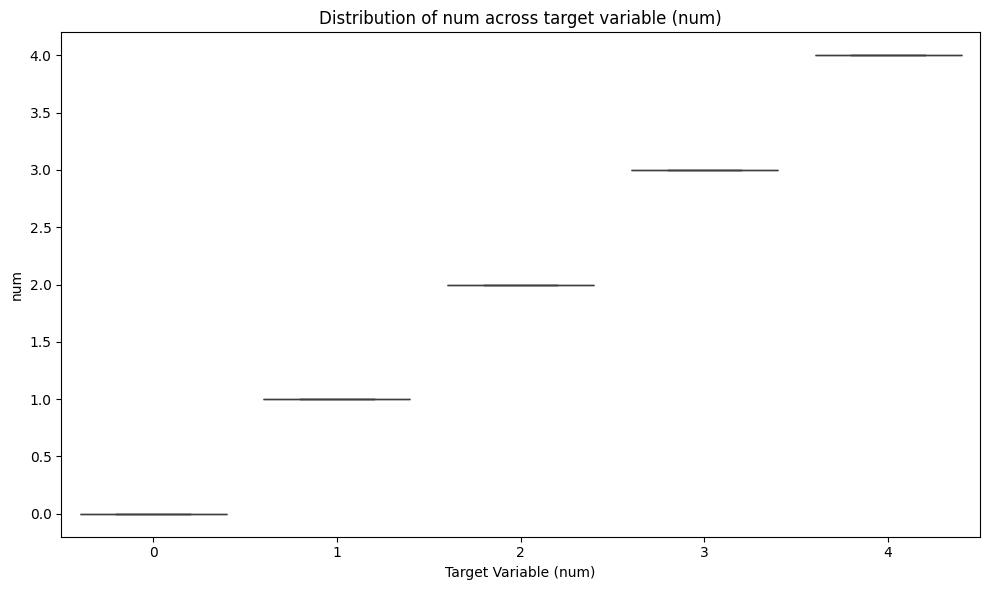

In [42]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'bool']).columns

for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=df, y=col, order=df[col].value_counts().index)
    plt.title(f'Distribution of {col}')
    plt.xlabel('Count')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

for col in df.columns:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, x='num', y=col)
    plt.title(f'Distribution of {col} across target variable (num)')
    plt.xlabel('Target Variable (num)')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

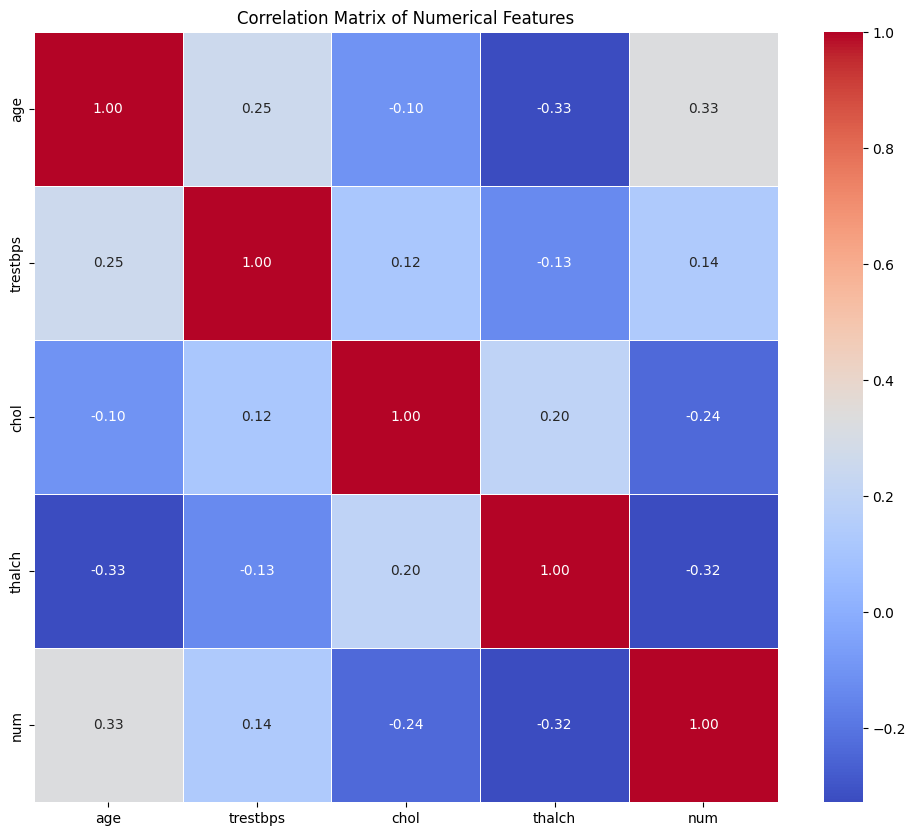

In [43]:
plt.figure(figsize=(12, 10))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### pre processing

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       908 non-null    int64 
 1   sex       908 non-null    object
 2   cp        908 non-null    object
 3   trestbps  908 non-null    int64 
 4   chol      908 non-null    int64 
 5   fbs       908 non-null    bool  
 6   restecg   908 non-null    object
 7   thalch    908 non-null    int64 
 8   exang     908 non-null    object
 9   slope     908 non-null    object
 10  thal      908 non-null    object
 11  num       908 non-null    int64 
dtypes: bool(1), int64(5), object(6)
memory usage: 79.0+ KB


In [46]:
x_cont= df[df.columns[[0,3,4,7,11]]]

from sklearn.preprocessing import StandardScaler
SS = StandardScaler()
SS_X = SS.fit_transform(x_cont)
SS_X = pd.DataFrame(SS_X)
SS_X.columns = list(df.columns[[0,3,4,7,11]])
SS_X

,age,trestbps,chol,thalch,num
0,1.006027,0.567394,0.281297,0.524183,-0.881977
1,-1.397560,0.076967,0.013526,-0.147705,-0.881977
2,0.350503,0.322181,-0.084656,0.449529,-0.881977
3,-0.195767,-0.756760,-0.138211,2.017268,-0.881977
4,0.350503,-1.149102,-0.004325,-0.371668,-0.881977
...,...,...,...,...,...
903,-0.086513,-0.413461,-1.798388,-0.595631,2.615119
904,0.896773,1.597292,-0.281021,-0.595631,2.615119
905,0.241249,1.793463,-1.798388,-0.483649,2.615119
906,0.241249,0.518352,0.058155,-1.155538,2.615119


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   age       908 non-null    int64 
 1   sex       908 non-null    object
 2   cp        908 non-null    object
 3   trestbps  908 non-null    int64 
 4   chol      908 non-null    int64 
 5   fbs       908 non-null    bool  
 6   restecg   908 non-null    object
 7   thalch    908 non-null    int64 
 8   exang     908 non-null    object
 9   slope     908 non-null    object
 10  thal      908 non-null    object
 11  num       908 non-null    int64 
dtypes: bool(1), int64(5), object(6)
memory usage: 79.0+ KB


In [48]:
le = LabelEncoder()
categorical_cols = df.select_dtypes(include=['object', 'bool']).columns
for col in categorical_cols:
    df[col] = le.fit_transform(df[[col]])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   age       908 non-null    int64
 1   sex       908 non-null    int32
 2   cp        908 non-null    int32
 3   trestbps  908 non-null    int64
 4   chol      908 non-null    int64
 5   fbs       908 non-null    int64
 6   restecg   908 non-null    int32
 7   thalch    908 non-null    int64
 8   exang     908 non-null    int32
 9   slope     908 non-null    int32
 10  thal      908 non-null    int32
 11  num       908 non-null    int64
dtypes: int32(6), int64(6)
memory usage: 64.0 KB


c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_label.p

In [49]:
df_cat = df[df.columns[[1,2,5,6,8,9,10]]]
df_cat

,sex,cp,fbs,restecg,exang,slope,thal
0,1,3,1,0,0,0,0
1,1,1,0,1,0,1,0
2,1,0,0,1,0,1,0
3,1,3,0,0,0,1,0
4,1,0,0,1,1,1,0
...,...,...,...,...,...,...,...
903,1,0,0,1,0,2,2
904,1,0,0,2,1,1,2
905,1,2,0,0,1,0,1
906,1,2,1,2,1,0,0


In [50]:
df_new = pd.concat([SS_X,df_cat],axis=1)
df_new

,age,trestbps,chol,thalch,num,sex,cp,fbs,restecg,exang,slope,thal
0,1.006027,0.567394,0.281297,0.524183,-0.881977,1,3,1,0,0,0,0
1,-1.397560,0.076967,0.013526,-0.147705,-0.881977,1,1,0,1,0,1,0
2,0.350503,0.322181,-0.084656,0.449529,-0.881977,1,0,0,1,0,1,0
3,-0.195767,-0.756760,-0.138211,2.017268,-0.881977,1,3,0,0,0,1,0
4,0.350503,-1.149102,-0.004325,-0.371668,-0.881977,1,0,0,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
903,-0.086513,-0.413461,-1.798388,-0.595631,2.615119,1,0,0,1,0,2,2
904,0.896773,1.597292,-0.281021,-0.595631,2.615119,1,0,0,2,1,1,2
905,0.241249,1.793463,-1.798388,-0.483649,2.615119,1,2,0,0,1,0,1
906,0.241249,0.518352,0.058155,-1.155538,2.615119,1,2,1,2,1,0,0


### model fitting

In [56]:
from sklearn.model_selection import train_test_split
X= df.drop('num', axis=1)
Y = df['num']
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [57]:
#---------------------------------------------------------1
from sklearn.tree import DecisionTreeClassifier   # decision tree regressor
model = DecisionTreeClassifier(criterion='gini') # entropy
model.fit(X_train,y_train)

Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

from sklearn.metrics import accuracy_score, log_loss
training_accuracy  = accuracy_score(y_train,Y_pred_train)
test_accuracy  = accuracy_score(y_test,Y_pred_test)

import numpy as np
print("trianing accuracy:", np.round(training_accuracy,2))
print("test accuracy:", np.round(test_accuracy,2))



trianing accuracy: 1.0
test accuracy: 0.5


In [58]:
#---------------------------------------------------------1
from sklearn.tree import DecisionTreeClassifier   # decision tree regressor
model = DecisionTreeClassifier(criterion='gini', max_depth=7) # entropy
model.fit(X_train,y_train)

Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

from sklearn.metrics import accuracy_score, log_loss
training_accuracy  = accuracy_score(y_train,Y_pred_train)
test_accuracy  = accuracy_score(y_test,Y_pred_test)

import numpy as np
print("trianing accuracy:", np.round(training_accuracy,2))
print("test accuracy:", np.round(test_accuracy,2))



trianing accuracy: 0.76
test accuracy: 0.56


In [59]:
#=============================================================
# shuffle split
#=============================================================
training_accracy = []
test_accuracy = []
training_loss = []
test_loss = []

for i in range(1, 501):
    model = DecisionTreeClassifier(criterion='gini',max_depth=7) # 'entropy' generally maxDepth is null
    model.fit(X_train,y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)
    training_accracy.append(accuracy_score(y_train,y_pred_train))
    test_accuracy.append(accuracy_score(y_test,y_pred_test))

print("Cross validation: Training accuracy score:", np.round(np.mean(training_accracy),2))
print("Cross validation: Test accuracy score:", np.round(np.mean(test_accuracy),2))


Cross validation: Training accuracy score: 0.76
Cross validation: Test accuracy score: 0.56


In [60]:
# prompt: count the total number of nodes and depth of the tree from above

from sklearn.tree import DecisionTreeClassifier
# ... (Your existing code) ...

# Assuming 'model' is your trained DecisionTreeClassifier
n_nodes = model.tree_.node_count
depth = model.tree_.max_depth

print(f"Number of nodes: {n_nodes}")
print(f"Depth of the tree: {depth}")


Number of nodes: 169
Depth of the tree: 7


### bagging with different parameters using grid search

In [61]:
from sklearn.ensemble import BaggingClassifier  # bagging regressor
from sklearn.model_selection import GridSearchCV
# prompt: use grid search cv to the above bagging classifier as decision tree estimator and give the different parameters for max_features, max_samples, n_estimators



# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.6, 0.7, 0.8],
    'max_features': [0.6, 0.7, 0.8]
}

# Create the bagging classifier with a decision tree estimator
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(criterion='gini'), random_state=42)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=bagging_model, param_grid=param_grid, cv=10, scoring='accuracy')
# Fit the grid search to the data
grid_search.fit(X_train, y_train)


# Print the best parameters and the best score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_accuracy)


Best parameters: {'max_features': 0.6, 'max_samples': 0.6, 'n_estimators': 200}
Best score: 0.575875190258752
Test accuracy: 0.5989010989010989


### analyse

we are getting accuracy 1

In [62]:
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [63]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Use the trained model to make predictions on the testing features
y_pred = dt_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

# Print the calculated evaluation metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision (weighted): {precision:.4f}")
print(f"Recall (weighted): {recall:.4f}")
print(f"F1-score (weighted): {f1:.4f}")

Accuracy: 0.5330
Precision (weighted): 0.5366
Recall (weighted): 0.5330
F1-score (weighted): 0.5333


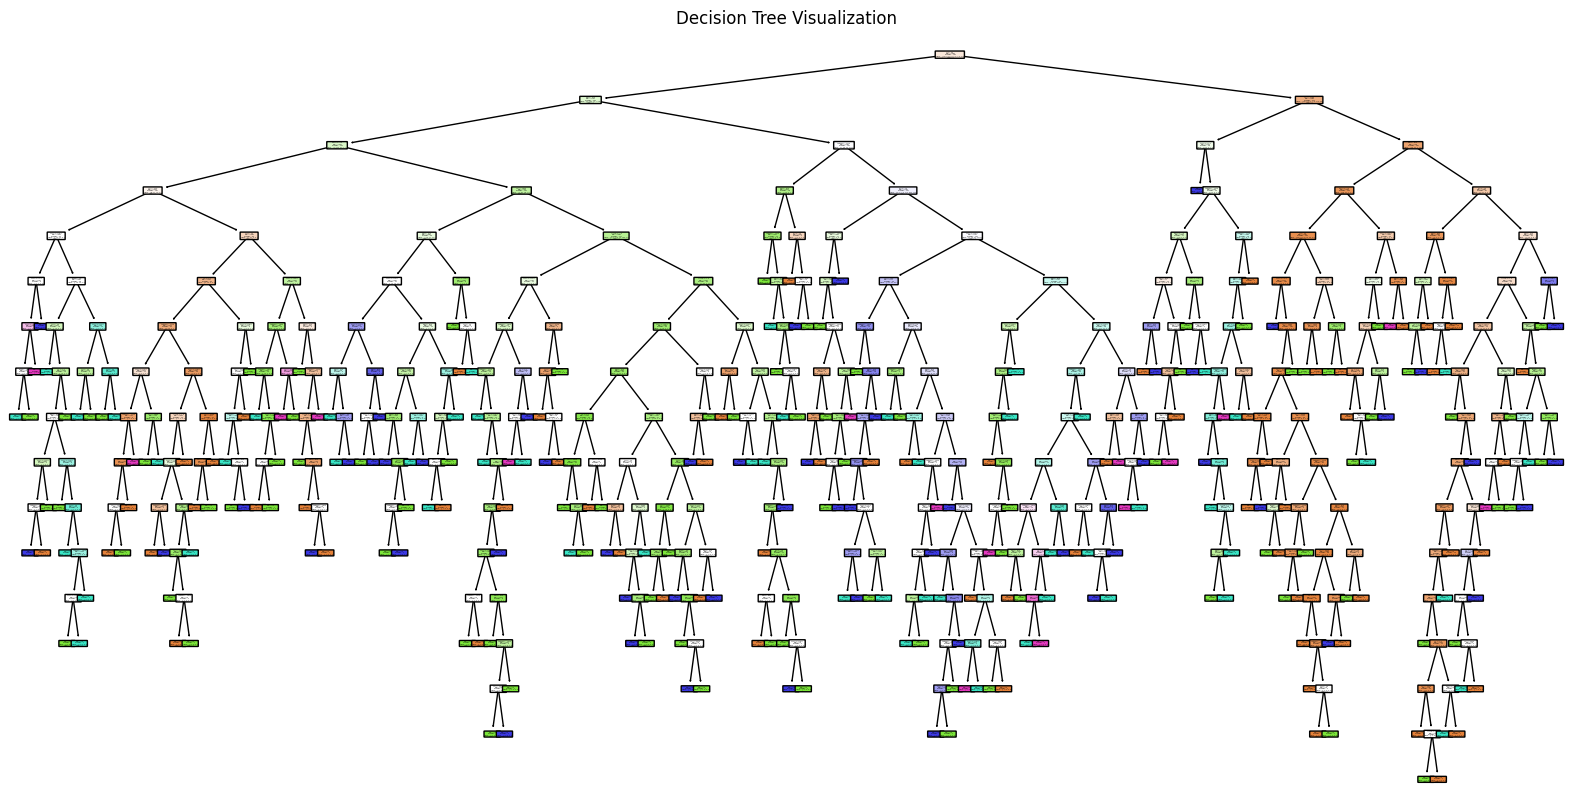

In [64]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
plot_tree(dt_classifier, filled=True, feature_names=X.columns.tolist(), class_names=[str(i) for i in sorted(Y.unique())], rounded=True)
plt.title('Decision Tree Visualization')
plt.show()

### Interview questions

1.  **What are some common hyperparameters of decision tree models, and how do they affect the model's performance?**

    *   `max_depth`: Limits the maximum depth of the tree. Smaller values prevent overfitting by limiting complexity, while larger values can lead to overfitting but potentially better capture complex relationships.
    *   `min_samples_split`: The minimum number of samples required to split an internal node. Larger values prevent the tree from splitting on small groups of samples, which can help with generalization but might miss important patterns.
    *   `min_samples_leaf`: The minimum number of samples required to be at a leaf node. Similar to `min_samples_split`, larger values prevent the creation of leaf nodes with very few samples, which can help with robustness.
2.  **What is the difference between the Label encoding and One-hot encoding?**

    *   **Label Encoding:** Assigns a unique integer to each category in a categorical feature. This is suitable for ordinal features where there is an inherent order (e.g., 'small', 'medium', 'large' could be encoded as 0, 1, 2). However, it can introduce an artificial sense of order or numerical relationship between categories if the feature is nominal (no inherent order).
    *   **One-Hot Encoding:** Creates new binary columns for each category in a categorical feature. A value of 1 in a new column indicates the presence of that category, and 0 otherwise. This is suitable for nominal features as it avoids implying any order or numerical relationship between categories.